In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
def generate_colored_dataset(seed=None):
    """
    Generates a synthetic 2D dataset with three clusters (red, green, yellow),
    each drawn from a distinct normal distribution with random mean, variance,
    and size.
    
    Returns
    -------
    df : pandas.DataFrame
        Dataset with columns ['x', 'y', 'category'].
    """
    if seed is not None:
        np.random.seed(seed)
    
    # Define categories and color labels
    colors = ['red', 'green', 'yellow']
    data = []

    for color in colors:
        # Random cluster size between 50 and 100
        n = np.random.randint(50, 101)
        
        # Random means between -5 and 5
        mean_x = np.random.uniform(-5, 5)
        mean_y = np.random.uniform(-5, 5)
        
        # Random standard deviations between 0.5 and 1.5
        std_x = np.random.uniform(0.5, 1.5)
        std_y = np.random.uniform(0.5, 1.5)
        
        # Generate cluster points
        x = np.random.normal(loc=mean_x, scale=std_x, size=n)
        y = np.random.normal(loc=mean_y, scale=std_y, size=n)
        
        # Store results
        cluster = pd.DataFrame({'x': x, 'y': y, 'category': color})
        data.append(cluster)

    # Concatenate all clusters
    df = pd.concat(data, ignore_index=True)
    return df

In [4]:
# Generando Datos
df = generate_colored_dataset(seed=42)
# Shuffle the dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.head()

,x,y,category
0,3.050731,-3.430410,red
1,3.067590,-3.543057,red
2,2.504684,2.508823,yellow
3,3.867588,-6.323985,red
4,-2.805400,-4.828940,green


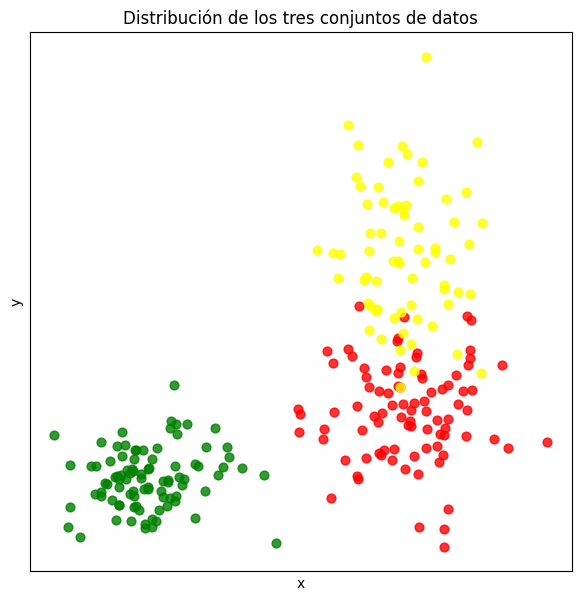

In [6]:
# Visualizando puntos

plt.figure(figsize=(7, 7))
for color in df['category'].unique():
    subset = df[df['category'] == color]
    plt.scatter(subset['x'], subset['y'], color=color, s=40, alpha=0.8)

plt.title("Distribución de los tres conjuntos de datos")
plt.xlabel("x")
plt.ylabel("y")
plt.xticks([])
plt.yticks([])
plt.show()

In [7]:
# Entrenamiento de un árbol de decisión sobre los datos generados
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# X: features, y: etiquetas
X = df[['x', 'y']].values
y = df['category'].values  # cadenas 'red', 'green', 'yellow'

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Modelo: Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

# Evaluación
y_pred = dt.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Accuracy (test): {acc:.3f}")
print(f"Depth: {dt.get_depth()} | Leaves: {dt.get_n_leaves()}")

Accuracy (test): 0.935
Depth: 7 | Leaves: 14


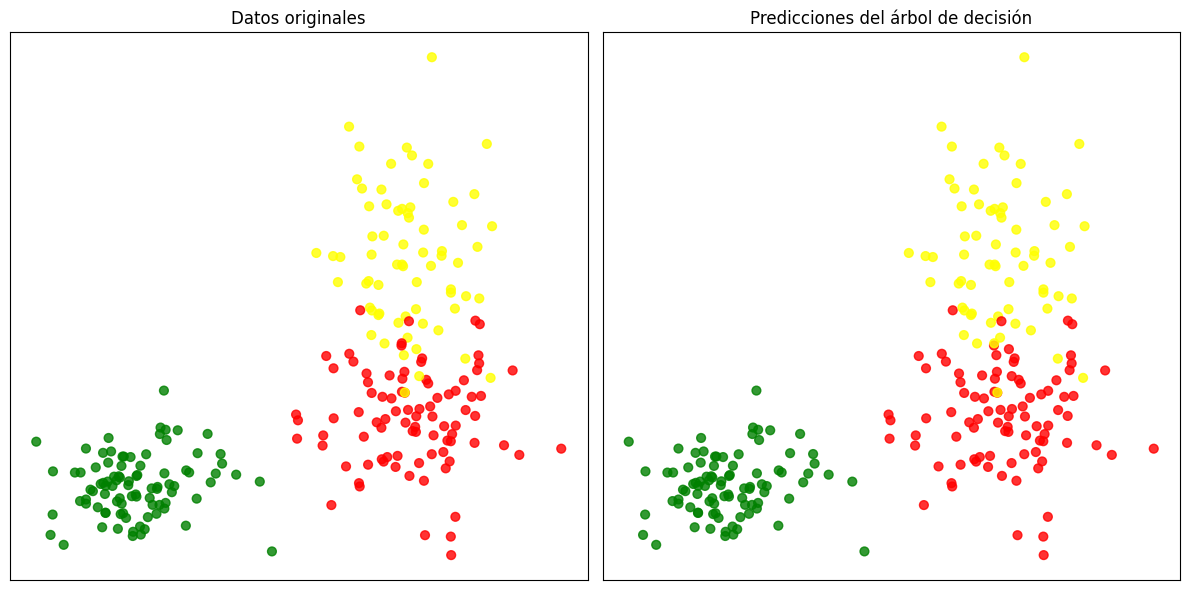

In [9]:
# Predicciones para todos los datos
y_pred_all = dt.predict(X)

# Figura comparativa: izquierda = originales, derecha = predicciones
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
titles = ["Datos originales", "Predicciones del árbol de decisión"]

# Izquierda: etiquetas originales
axes[0].scatter(df['x'], df['y'], c=df['category'], s=40, alpha=0.8)
axes[0].set_title(titles[0])
axes[0].set_xticks([])
axes[0].set_yticks([])

# Derecha: etiquetas predichas por el modelo
axes[1].scatter(df['x'], df['y'], c=y_pred_all, s=40, alpha=0.8)
axes[1].set_title(titles[1])
axes[1].set_xticks([])
axes[1].set_yticks([])

plt.tight_layout()
plt.show()